# PC.3 (b) — Método do Gradiente Estocástico na Função de Himmelblau

$$f(x,y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2$$

A função possui **quatro mínimos globais** (todos com $f = 0$):

| Mínimo | $x$ | $y$ |
|---|---|---|
| $M_1$ | 3,0000 | 2,0000 |
| $M_2$ | −2,8051 | 3,1313 |
| $M_3$ | −3,7793 | −3,2832 |
| $M_4$ | 3,5844 | −1,8481 |

**Como tornar o problema "estocástico"?** A função de Himmelblau não depende de um conjunto de dados, mas pode ser vista como a soma de $N = 2$ termos ("amostras"):

$$f(x,y) = \underbrace{(x^2 + y - 11)^2}_{f_1} + \underbrace{(x + y^2 - 7)^2}_{f_2}$$

Assim como no material da disciplina, em que o SGD atualiza os parâmetros usando o gradiente de **uma única amostra** por vez, aqui a cada iteração sorteia-se um dos termos $f_i$ e faz-se

$$\mathbf{x}_k = \mathbf{x}_{k-1} - \eta \, N \, \nabla f_i(\mathbf{x}_{k-1})$$

O fator $N$ torna o estimador **não-viesado**: $\mathbb{E}[N\nabla f_i] = \nabla f$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 100

# mínimos conhecidos (para referência nos gráficos)
MINIMOS = np.array([[3.0, 2.0], [-2.805118, 3.131312],
                    [-3.779310, -3.283186], [3.584428, -1.848126]])

## Função objetivo e gradientes

Gradiente de cada termo:

$$\nabla f_1 = \begin{bmatrix} 4x\,r_1 \\ 2\,r_1 \end{bmatrix}, \quad
\nabla f_2 = \begin{bmatrix} 2\,r_2 \\ 4y\,r_2 \end{bmatrix}, \quad
r_1 = x^2 + y - 11, \; r_2 = x + y^2 - 7$$

In [2]:
def f(p):
    x, y = p
    return (x**2 + y - 11)**2 + (x + y**2 - 7)**2

def grad_termos(p):
    # retorna o gradiente de f1 e de f2 separadamente
    x, y = p
    r1 = x**2 + y - 11
    r2 = x + y**2 - 7
    g1 = np.array([4*x*r1, 2*r1])
    g2 = np.array([2*r2, 4*y*r2])
    return g1, g2

def grad(p):
    g1, g2 = grad_termos(p)
    return g1 + g2

Função auxiliar para desenhar as curvas de nível. A escala logarítmica nos níveis ajuda a enxergar os vales perto dos mínimos.

In [3]:
xx, yy = np.meshgrid(np.linspace(-5, 5, 400), np.linspace(-5, 5, 400))
ZZ = f((xx, yy))

def plot_contorno(ax, titulo=''):
    niveis = np.logspace(-1, 3, 25)
    ax.contour(xx, yy, ZZ, levels=niveis, cmap='viridis', linewidths=0.7)
    ax.plot(MINIMOS[:, 0], MINIMOS[:, 1], 'k*', ms=10)
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.set_title(titulo)
    ax.set_aspect('equal')

## Visualização da função


Use os botões > e o slider abaixo do gráfico para girar a superfície e ver os quatro "vales" (mínimos) por vários ângulos.

In [4]:
from matplotlib import animation
from IPython.display import HTML

plt.rcParams['animation.embed_limit'] = 50  # MB

Xs, Ys = np.meshgrid(np.linspace(-5, 5, 80), np.linspace(-5, 5, 80))
Zs = f((Xs, Ys))

fig = plt.figure(figsize=(6.5, 5.5), dpi=75)
ax = fig.add_subplot(projection='3d')
ax.plot_surface(Xs, Ys, Zs, cmap='viridis', rstride=1, cstride=1, linewidth=0, alpha=0.95)
ax.contour(Xs, Ys, Zs, levels=np.logspace(-1, 3, 15), zdir='z', offset=0,
           cmap='viridis', linewidths=0.6)  # curvas de nível projetadas no "chão"
ax.scatter(MINIMOS[:, 0], MINIMOS[:, 1], 0, c='red', s=40, depthshade=False)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('f(x, y)')
ax.set_title('Função de Himmelblau')

def girar(i):
    ax.view_init(elev=30 + 15*np.sin(2*np.pi*i/48), azim=i*7.5)  # volta completa em 48 quadros
    return []

anim = animation.FuncAnimation(fig, girar, frames=48, interval=100)
plt.close(fig)
HTML(anim.to_jshtml())

### Mapa de calor e campo de gradiente

As setas mostram $-\nabla f$ normalizado, isto é, a direção em que o método do gradiente se move a partir de cada ponto. Nota-se que as setas "escoam" para os quatro mínimos. A escala logarítmica de cores realça os vales.

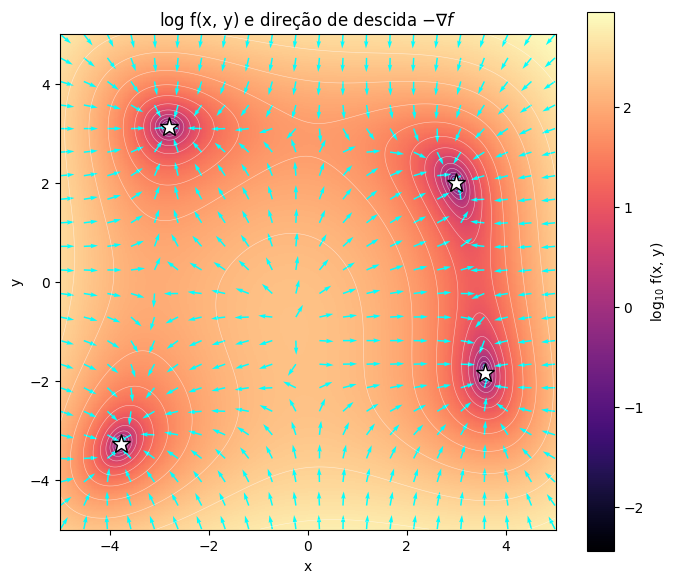

In [5]:
xg, yg = np.meshgrid(np.linspace(-5, 5, 22), np.linspace(-5, 5, 22))
gx, gy = grad((xg, yg))
norma = np.hypot(gx, gy) + 1e-12

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(xx, yy, np.log10(ZZ + 1e-3), cmap='magma', shading='auto')
ax.contour(xx, yy, ZZ, levels=np.logspace(-1, 3, 15), colors='white', linewidths=0.4, alpha=0.6)
ax.quiver(xg, yg, -gx/norma, -gy/norma, color='cyan', scale=35, width=0.003)
ax.plot(MINIMOS[:, 0], MINIMOS[:, 1], 'w*', ms=14, mec='k')
fig.colorbar(im, ax=ax, label='log$_{10}$ f(x, y)')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
ax.set_title('log f(x, y) e direção de descida $-\\nabla f$')
plt.show()

### Bacias de atração

Cada ponto do plano é colorido pelo mínimo ao qual o **gradiente determinístico** converge partindo dali. Isso antecipa o que será visto no Experimento 2: o ponto inicial decide qual mínimo é encontrado. As fronteiras entre as cores passam pelos pontos de sela e pelo máximo local da função.

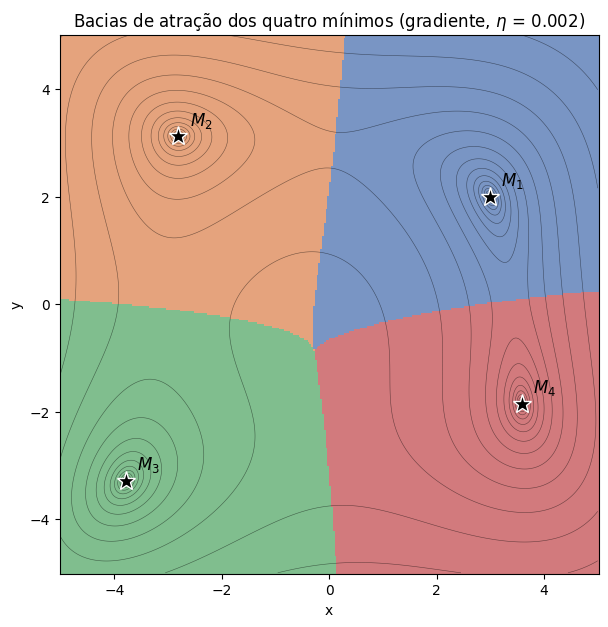

In [6]:
# gradiente aplicado a todos os pontos da grade de uma só vez (vetorizado)
gx0, gy0 = np.meshgrid(np.linspace(-5, 5, 300), np.linspace(-5, 5, 300))
P = np.stack([gx0, gy0])
for _ in range(3000):
    P = P - 0.002 * np.stack(grad(P))
    P = np.clip(P, -10, 10)

# índice do mínimo mais próximo do ponto final
dist = np.linalg.norm(P[None] - MINIMOS[:, :, None, None], axis=1)
bacia = dist.argmin(axis=0)

cores_bacia = plt.matplotlib.colors.ListedColormap(['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
fig, ax = plt.subplots(figsize=(8, 7))
ax.pcolormesh(gx0, gy0, bacia, cmap=cores_bacia, shading='auto', alpha=0.75)
ax.contour(xx, yy, ZZ, levels=np.logspace(-1, 3, 15), colors='k', linewidths=0.4, alpha=0.5)
for i, (mx, my) in enumerate(MINIMOS):
    ax.plot(mx, my, 'k*', ms=14, mec='w')
    ax.annotate(f'$M_{i+1}$', (mx, my), xytext=(8, 8), textcoords='offset points', fontsize=12, weight='bold')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
ax.set_title('Bacias de atração dos quatro mínimos (gradiente, $\\eta$ = 0.002)')
plt.show()

## Implementação do SGD

Parâmetros:
- `eta`: taxa de aprendizado $\eta$;
- `sigma`: desvio-padrão de um ruído gaussiano extra somado ao gradiente (simula medições ruidosas, usado no experimento 4);
- `decay`: decaimento da taxa, $\eta_k = \eta / (1 + \text{decay}\cdot k)$;
- `seed`: semente do gerador aleatório.

A execução é interrompida se a solução divergir.

In [7]:
def sgd(p0, eta, n_iter=500, sigma=0.0, decay=0.0, seed=0):
    rng = np.random.default_rng(seed)
    p = np.array(p0, dtype=float)
    traj, fs = [p.copy()], [f(p)]
    N = 2  # número de "amostras" (termos da soma)

    for k in range(n_iter):
        g1, g2 = grad_termos(p)
        g = N * (g1 if rng.integers(N) == 0 else g2)  # gradiente de um termo sorteado
        if sigma > 0:
            g = g + sigma * rng.standard_normal(2)

        eta_k = eta / (1 + decay * k)
        p = p - eta_k * g

        if not np.all(np.isfinite(p)) or np.linalg.norm(p) > 1e3:
            print(f'  -> divergiu na iteração {k+1} (eta={eta})')
            break
        traj.append(p.copy())
        fs.append(f(p))

    return np.array(traj), np.array(fs)

## Experimento 1 — Variação da taxa de aprendizado $\eta$

Ponto inicial fixo $(0, 0)$, 500 iterações, mesma semente.

In [8]:
etas = [0.001, 0.005, 0.01, 0.015, 0.02]
p0 = (0, 0)
res_eta = {}
for eta in etas:
    res_eta[eta] = sgd(p0, eta, n_iter=500, seed=0)
    t, fs = res_eta[eta]
    print(f'eta={eta:<6} iterações={len(t)-1:<4} ponto final=({t[-1,0]:.4f}, {t[-1,1]:.4f})  f={fs[-1]:.2e}')

eta=0.001  iterações=500  ponto final=(3.0000, 2.0000)  f=2.13e-11
eta=0.005  iterações=500  ponto final=(3.0000, 2.0000)  f=6.31e-30
eta=0.01   iterações=500  ponto final=(3.0000, 2.0000)  f=0.00e+00
eta=0.015  iterações=500  ponto final=(2.8687, 2.0327)  f=5.44e-01
  -> divergiu na iteração 143 (eta=0.02)
eta=0.02   iterações=142  ponto final=(-28.5063, -190.0904)  f=1.30e+09


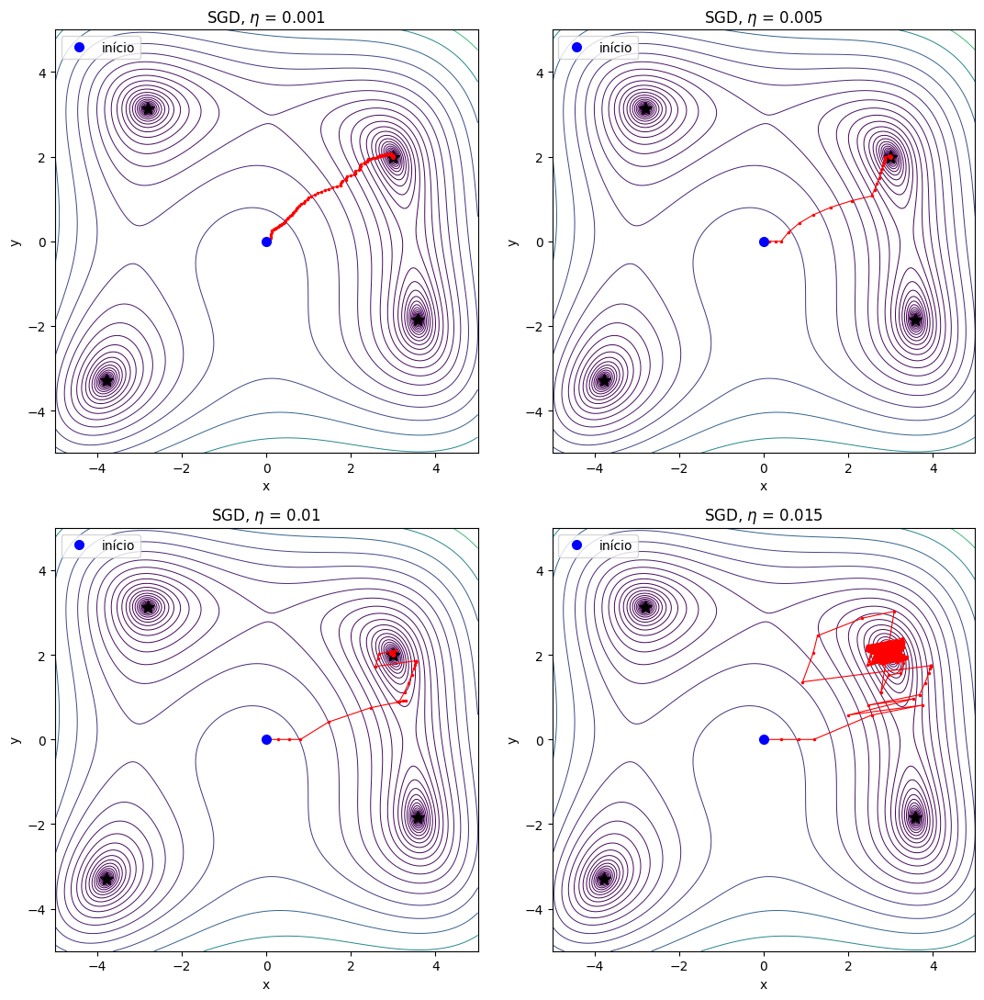

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(11, 11))
for ax, eta in zip(axs.ravel(), etas[:4]):
    t, _ = res_eta[eta]
    plot_contorno(ax, f'SGD, $\\eta$ = {eta}')
    ax.plot(t[:, 0], t[:, 1], 'r.-', ms=3, lw=0.8)
    ax.plot(*t[0], 'bo', ms=7, label='início')
    ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

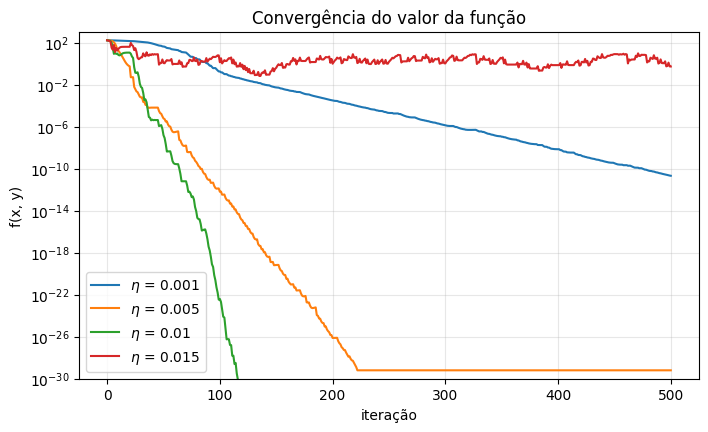

In [10]:
plt.figure(figsize=(8, 4.5))
for eta in etas[:4]:
    _, fs = res_eta[eta]
    plt.semilogy(fs + 1e-32, label=f'$\\eta$ = {eta}')
plt.xlabel('iteração'); plt.ylabel('f(x, y)')
plt.title('Convergência do valor da função')
plt.ylim(1e-30, 1e3)
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Observações:**
- $\eta = 0{,}001$: trajetória suave, mas lenta, ainda não atingiu precisão de máquina em 500 iterações.
- $\eta = 0{,}005$ e $0{,}01$: convergência rápida até $M_1 = (3, 2)$, os "zigue-zagues" vêm da alternância aleatória entre os dois termos.
- $\eta = 0{,}015$: o passo já é grande demais perto do mínimo, a solução fica oscilando em torno de $M_1$ sem convergir.
- $\eta = 0{,}02$: **diverge**. Como o gradiente de um único termo tem módulo maior (fator $N=2$) que o gradiente completo, o SGD tolera taxas menores que o gradiente determinístico.

## Experimento 2 — Variação do ponto inicial

Com $\eta = 0{,}005$ e 1000 iterações, partindo de pontos diferentes do domínio.

início=(0, 0)    -> ( 3.0000,  2.0000)  f=6.3e-30
início=(-1, 0)   -> (-2.8051,  3.1313)  f=7.9e-31
início=(-4, 4)   -> (-2.8051,  3.1313)  f=7.9e-31
início=(-1, -1)  -> (-3.7793, -3.2832)  f=7.9e-31
início=(0, -4)   -> (-3.7793, -3.2832)  f=7.9e-31
início=(4, -4)   -> ( 3.5844, -1.8481)  f=0.0e+00
início=(1, 4)    -> ( 3.0000,  2.0000)  f=6.3e-30
início=(-4, -1)  -> (-3.7793, -3.2832)  f=7.9e-31


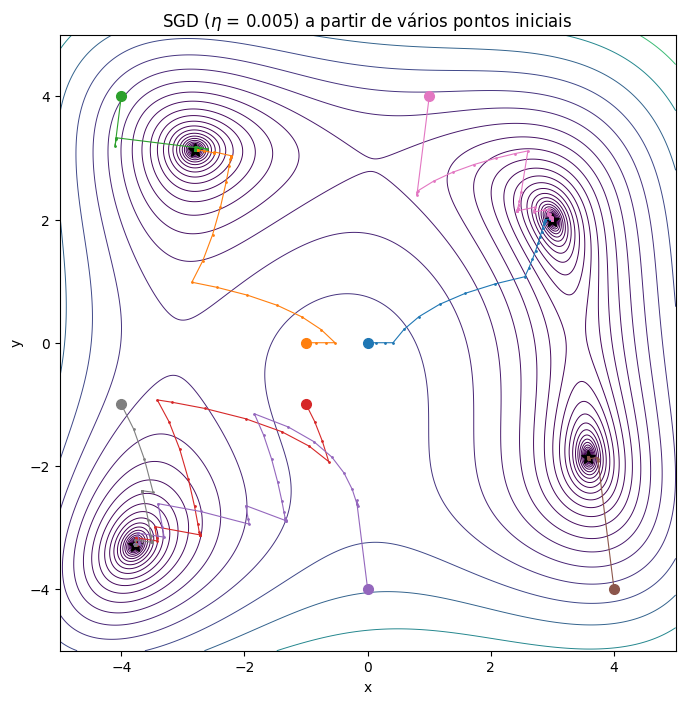

In [11]:
pontos_iniciais = [(0, 0), (-1, 0), (-4, 4), (-1, -1), (0, -4), (4, -4), (1, 4), (-4, -1)]
cores = plt.cm.tab10(np.arange(len(pontos_iniciais)))

fig, ax = plt.subplots(figsize=(8, 8))
plot_contorno(ax, 'SGD ($\\eta$ = 0.005) a partir de vários pontos iniciais')
for p0, c in zip(pontos_iniciais, cores):
    t, fs = sgd(p0, 0.005, n_iter=1000, seed=0)
    ax.plot(t[:, 0], t[:, 1], '.-', color=c, ms=2, lw=0.8)
    ax.plot(*t[0], 'o', color=c, ms=7)
    print(f'início={str(p0):<9} -> ({t[-1,0]:7.4f}, {t[-1,1]:7.4f})  f={fs[-1]:.1e}')
plt.show()

**Observações:** cada ponto inicial converge para o mínimo de cuja **bacia de atração** ele faz parte. Os quatro mínimos são alcançados. O SGD continua sendo um método **local**: o sorteio dos termos não é suficiente, aqui, para "saltar" de uma bacia para outra.

## Experimento 3 — Variação da semente aleatória

Mesmo ponto inicial e mesmo $\eta$, mudando apenas a sequência de sorteios.

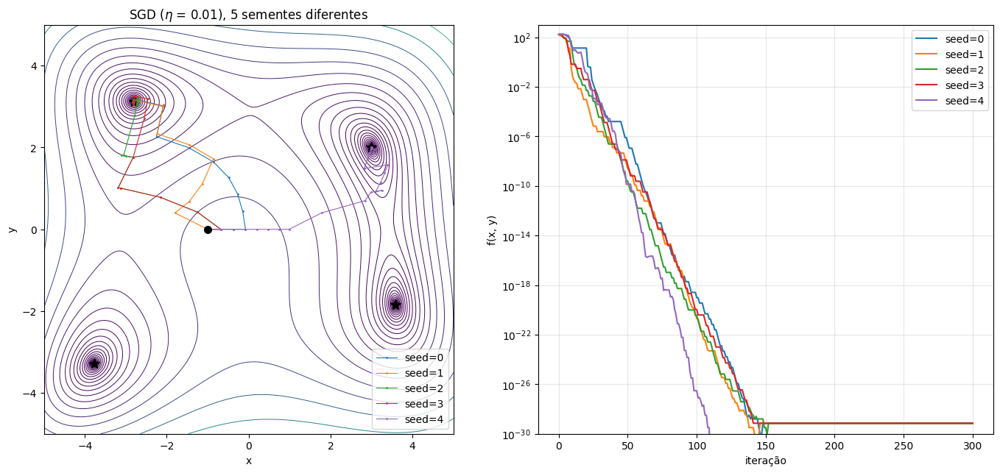

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
plot_contorno(axs[0], 'SGD ($\\eta$ = 0.01), 5 sementes diferentes')

for s in range(5):
    t, fs = sgd((-1, 0), 0.01, n_iter=300, seed=s)
    axs[0].plot(t[:, 0], t[:, 1], '.-', ms=2, lw=0.8, label=f'seed={s}')
    axs[1].semilogy(fs + 1e-32, label=f'seed={s}')

axs[0].plot(-1, 0, 'ko', ms=7)
axs[0].legend(loc='lower right')
axs[1].set_xlabel('iteração'); axs[1].set_ylabel('f(x, y)')
axs[1].set_ylim(1e-30, 1e3); axs[1].grid(alpha=0.3); axs[1].legend()
plt.tight_layout(); plt.show()

**Observações:** as trajetórias diferem em cada execução (natureza estocástica do método), mas, partindo de $(-1, 0)$, todas chegam ao mesmo mínimo $M_2$. O número de iterações necessário varia de uma semente para outra.



## Experimento 4 — Gradiente ruidoso e decaimento da taxa

Para reproduzir uma situação mais realista (em que o gradiente de cada amostra **não** se anula no ótimo), adiciona-se um ruído gaussiano $\mathcal{N}(0, \sigma^2)$ ao gradiente. Compara-se $\eta$ constante com $\eta_k = \eta / (1 + 0{,}01k)$.

sigma=0   decay=0.0   f_final=6.31e-30  dist. média ao mínimo (últimas 200 it.)=0.0000
sigma=0   decay=0.01  f_final=1.19e-27  dist. média ao mínimo (últimas 200 it.)=0.0000
sigma=5   decay=0.0   f_final=6.55e-02  dist. média ao mínimo (últimas 200 it.)=0.0587
sigma=5   decay=0.01  f_final=1.54e-03  dist. média ao mínimo (últimas 200 it.)=0.0211
sigma=20  decay=0.0   f_final=1.28e+00  dist. média ao mínimo (últimas 200 it.)=0.2213
sigma=20  decay=0.01  f_final=2.02e-02  dist. média ao mínimo (últimas 200 it.)=0.0840


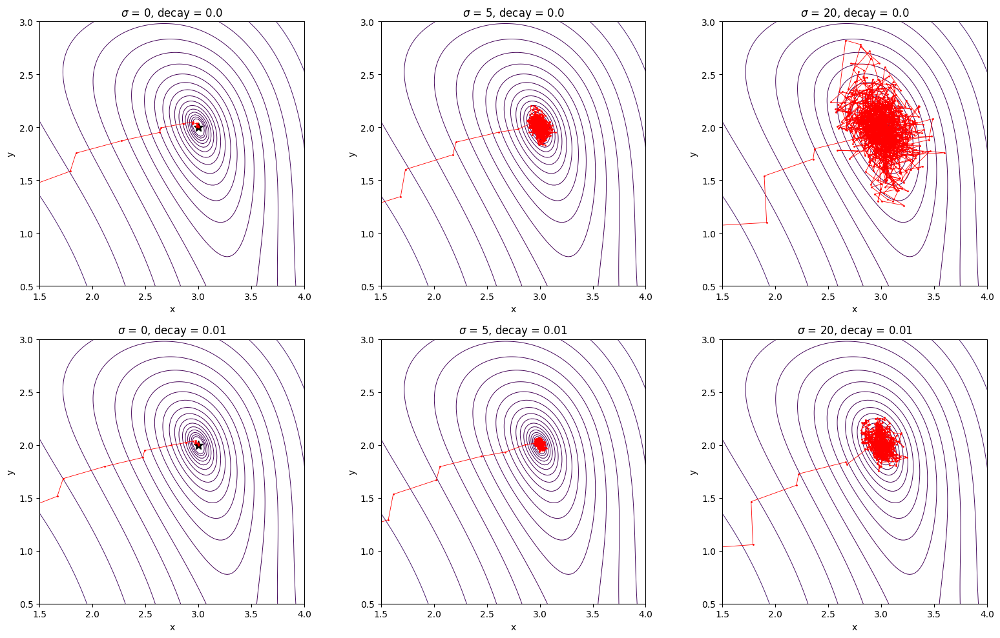

In [13]:
sigmas = [0, 5, 20]
fig, axs = plt.subplots(2, 3, figsize=(16, 10))

for j, sigma in enumerate(sigmas):
    for i, decay in enumerate([0.0, 0.01]):
        t, fs = sgd((0, 0), 0.005, n_iter=1000, sigma=sigma, decay=decay, seed=1)
        ax = axs[i, j]
        plot_contorno(ax, f'$\\sigma$ = {sigma}, decay = {decay}')
        ax.plot(t[:, 0], t[:, 1], 'r.-', ms=2, lw=0.6)
        # zoom na região do mínimo (3, 2)
        ax.set_xlim(1.5, 4); ax.set_ylim(0.5, 3)
        dist = np.linalg.norm(t[-200:] - MINIMOS[0], axis=1).mean()
        print(f'sigma={sigma:<3} decay={decay:<5} f_final={fs[-1]:.2e}  dist. média ao mínimo (últimas 200 it.)={dist:.4f}')

plt.tight_layout(); plt.show()

**Observações:**
- Sem ruído ($\sigma = 0$) o comportamento é o mesmo dos experimentos anteriores.
- Com ruído e $\eta$ constante, a solução se aproxima do mínimo mas fica **oscilando ao redor dele**, e a amplitude cresce com $\sigma$, exatamente a desvantagem do SGD citada no material.
- O decaimento da taxa reduz progressivamente o tamanho dos passos e faz a solução "assentar" bem mais perto do mínimo.

## Comparação: gradiente completo × gradiente estocástico

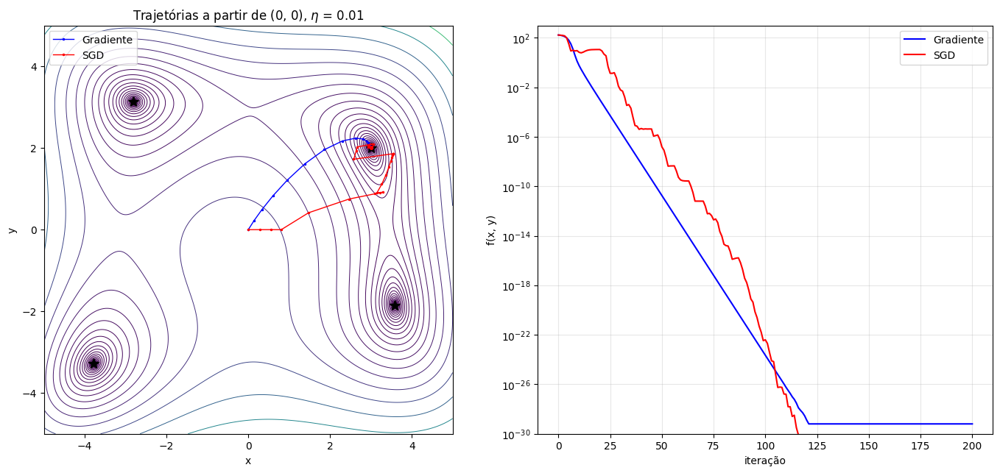

In [14]:
def gd(p0, eta, n_iter=500):
    # gradiente determinístico (usa os dois termos), apenas para comparação
    p = np.array(p0, dtype=float)
    traj, fs = [p.copy()], [f(p)]
    for _ in range(n_iter):
        p = p - eta * grad(p)
        traj.append(p.copy()); fs.append(f(p))
    return np.array(traj), np.array(fs)

t_gd, f_gd = gd((0, 0), 0.01, 200)
t_sgd, f_sgd = sgd((0, 0), 0.01, 200, seed=0)

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
plot_contorno(axs[0], 'Trajetórias a partir de (0, 0), $\\eta$ = 0.01')
axs[0].plot(t_gd[:, 0], t_gd[:, 1], 'b.-', ms=3, lw=1, label='Gradiente')
axs[0].plot(t_sgd[:, 0], t_sgd[:, 1], 'r.-', ms=3, lw=1, label='SGD')
axs[0].legend(loc='upper left')

axs[1].semilogy(f_gd + 1e-32, 'b', label='Gradiente')
axs[1].semilogy(f_sgd + 1e-32, 'r', label='SGD')
axs[1].set_xlabel('iteração'); axs[1].set_ylabel('f(x, y)')
axs[1].set_ylim(1e-30, 1e3); axs[1].grid(alpha=0.3); axs[1].legend()
plt.tight_layout(); plt.show()

**Observações:** o gradiente completo segue uma trajetória suave, perpendicular às curvas de nível. O SGD avança em "degraus", alternando entre as direções de $\nabla f_1$ e $\nabla f_2$, mas cada iteração custa a avaliação de apenas um termo. Neste problema com só 2 termos a economia é pequena, em problemas com milhares de amostras ela é a principal motivação do método.

## Discussão

- **Taxa de aprendizado** é o parâmetro mais crítico. Taxas pequenas convergem de forma estável porém lenta, taxas intermediárias ($\eta \approx 0{,}005$–$0{,}01$) dão o melhor resultado, a partir de $\eta \approx 0{,}015$ a solução oscila e com $\eta = 0{,}02$ diverge. O SGD é mais sensível a $\eta$ que o gradiente completo porque o gradiente de uma amostra tem maior variância.
- **Ponto inicial** determina para qual dos quatro mínimos o método converge. O SGD, por si só, não garante a busca do ótimo global, nesta função isso não é problema porque todos os mínimos têm $f = 0$.
- **Aleatoriedade (semente)** muda o caminho percorrido e a velocidade, mas não o destino quando a bacia de atração é bem definida.
- **Ruído no gradiente** causa oscilação persistente em torno do ótimo quando $\eta$ é constante. O **decaimento da taxa** é a solução clássica: passos grandes no início (progresso rápido) e pequenos no fim (precisão).
- Particularidade da Himmelblau: como os dois termos se anulam simultaneamente nos mínimos, o SGD sem ruído converge até a precisão de máquina, o que em geral não ocorre em problemas de ajuste com dados ruidosos.